```mermaid
flowchart TD
    %% Main Header
    DATASET["Dataset Variables<br>(11 Features + 1 Target)"]

    %% Main Categories
    DEM["Demographics"]
    FIN["Financial Information"]
    LOAN["Loan Information"]
    CB["Credit Bureau Information"]
    TAR["Target Variable"]

    %% Category Sub-nodes
    DEM_VARS["1. age<br>2. home_ownership"]
    FIN_VARS["3. employment_years<br>4. annual_income"]
    LOAN_VARS["5. loan_purpose<br>6. loan_amount<br>7. loan_interest_rate<br>8. loan_income_ratio"]
    CB_VARS["9. credit_grade<br>10. credit_history_years<br>11. previous_default_flag"]
    TAR_VAR["default_flag (0, 1)"]

    %% Connections
    DATASET --> DEM
    DATASET --> FIN
    DATASET --> LOAN
    DATASET --> CB
    DATASET --> TAR

    DEM --> DEM_VARS
    FIN --> FIN_VARS
    LOAN --> LOAN_VARS
    CB --> CB_VARS
    TAR --> TAR_VAR
```

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# Import Dataset

In [2]:
df = pd.read_csv("../01_data/credit_risk_dataset.csv",)
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# Rename Columns

In [3]:
rename_map = {
    "loan_status": "default_flag",
    "person_age": "age",
    "person_income": "annual_income",
    "person_emp_length": "employment_years",
    "loan_amnt": "loan_amount",
    "loan_int_rate": "interest_rate",
    "loan_percent_income": "loan_income_ratio",
    "cb_person_cred_hist_length": "credit_history_years",
    "person_home_ownership": "home_ownership",
    "loan_intent": "loan_purpose",
    "loan_grade": "credit_grade",
    "cb_person_default_on_file": "prior_default_flag"
}

df = df.rename(columns=rename_map)

In [4]:
df.head()

,age,annual_income,home_ownership,employment_years,loan_purpose,credit_grade,loan_amount,interest_rate,default_flag,loan_income_ratio,prior_default_flag,credit_history_years
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# Data Inspection

In [5]:
df.shape

(32581, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   32581 non-null  int64  
 1   annual_income         32581 non-null  int64  
 2   home_ownership        32581 non-null  object 
 3   employment_years      31686 non-null  float64
 4   loan_purpose          32581 non-null  object 
 5   credit_grade          32581 non-null  object 
 6   loan_amount           32581 non-null  int64  
 7   interest_rate         29465 non-null  float64
 8   default_flag          32581 non-null  int64  
 9   loan_income_ratio     32581 non-null  float64
 10  prior_default_flag    32581 non-null  object 
 11  credit_history_years  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
# check duplicate values
df.duplicated().sum()

165

In [8]:
# drop them
df.drop_duplicates(inplace=True)

In [9]:
# check missing values
df.isna().sum()

age                        0
annual_income              0
home_ownership             0
employment_years         887
loan_purpose               0
credit_grade               0
loan_amount                0
interest_rate           3095
default_flag               0
loan_income_ratio          0
prior_default_flag         0
credit_history_years       0
dtype: int64

In [10]:
# Q: How much % nan values in each cols
nan_percent_values = np.round(df.isnull().sum()/df.shape[0] * 100,2) 
nan_percent_values[nan_percent_values > 0]

employment_years    2.74
interest_rate       9.55
dtype: float64

We we do feature Engerning we handle the nan values their 

In [11]:
df.describe()

,age,annual_income,employment_years,loan_amount,interest_rate,default_flag,loan_income_ratio,credit_history_years
count,32416.000000,3.241600e+04,31529.00000,32416.000000,29321.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.79051,9593.845632,11.017265,0.218688,0.170250,5.811297
std,6.354100,6.201558e+04,4.14549,6322.730241,3.241680,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.00000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.00000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.00000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.00000,12250.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.00000,35000.000000,23.220000,1.000000,0.830000,30.000000


# EDA

## Target Varible

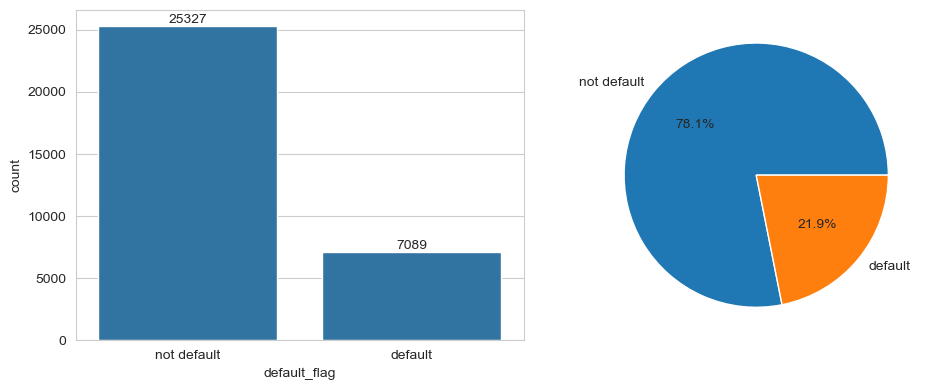

In [12]:
data = df["default_flag"].replace({0: "not default", 1: "default"})
counts = data.value_counts()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Bar plot with auto-numbers
sns.countplot(x=data, order=['not default','default'] ,ax=ax[0])
ax[0].bar_label(ax[0].containers[0])


ax[1].pie(
    [counts["not default"], counts["default"]],
    labels=["not default", "default"],
    autopct="%.1f%%",
    
)
plt.tight_layout()
plt.show()

Data is imbalanced

## Univarite Cateogrical Varible

In [13]:
categorical_columns = ['home_ownership', 'loan_purpose', 'credit_grade', 'prior_default_flag']

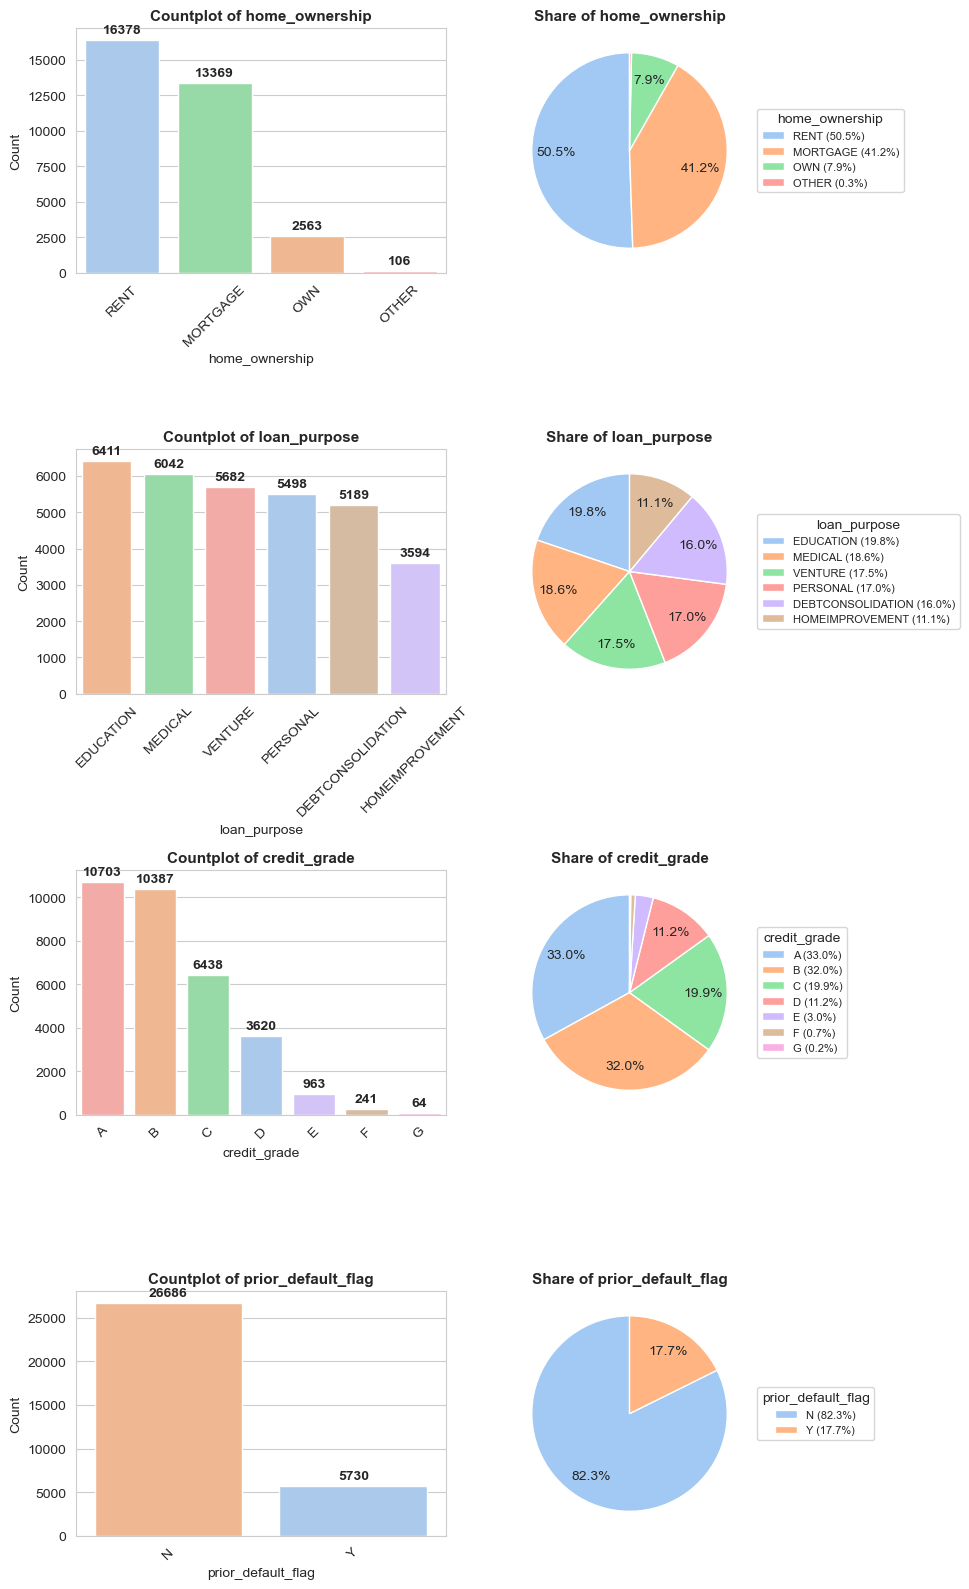

In [14]:
def univariate_categorical_plot(df, columns, figsize_per_row=(10, 4), palette="pastel", min_pct_to_label=3.0):
    """
    Plots a countplot (left, descending order, with count labels) and
    a pie chart (right, with percentage labels, legend-based) for each categorical column.
    """
    
    if isinstance(columns, str):
        columns = [columns]
    
    n = len(columns)
    n_rows = n
    n_cols = 2
    
    fig_width, row_height = figsize_per_row
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, row_height * n_rows))
    
    if n_rows == 1:
        axes = np.array([axes])
    
    for i, column in enumerate(columns):
        data = df[column]
        counts = data.value_counts()
        pct = counts / counts.sum() * 100
        
        # ---------- Left: Countplot ----------
        ax = axes[i, 0]
        sns.countplot(
            data=df,
            x=column,
            hue=column,
            order=counts.index,
            ax=ax,
            palette=palette,
            legend=False
        )
        
        # Add count labels on top of each bar
        for container in ax.containers:
            ax.bar_label(
                container,
                labels=[str(int(v.get_height())) for v in container],
                fontsize=10,
                fontweight='bold',
                padding=3
            )
        
        ax.set_title(f"Countplot of {column}", fontsize=11, fontweight="bold")
        ax.set_xlabel(column)
        ax.set_ylabel("Count")
        ax.tick_params(axis='x', rotation=45)
        
        # ---------- Right: Pie chart ----------
        colors = sns.color_palette(palette, len(counts))
        
        def make_autopct(pct_values, threshold):
            def autopct_fn(pct):
                return f"{pct:.1f}%" if pct >= threshold else ""
            return autopct_fn
        
        wedges, texts, autotexts = axes[i, 1].pie(
            counts.values,
            labels=None,
            autopct=make_autopct(pct, min_pct_to_label),
            pctdistance=0.75,
            startangle=90,
            colors=colors
        )
        
        legend_labels = [f"{cat} ({p:.1f}%)" for cat, p in zip(counts.index, pct)]
        axes[i, 1].legend(
            wedges, legend_labels,
            title=column,
            loc="center left",
            bbox_to_anchor=(1.0, 0.5),
            fontsize=8
        )
        
        axes[i, 1].set_title(f"Share of {column}", fontsize=11, fontweight="bold")
    
    plt.tight_layout()
    plt.show()
    
univariate_categorical_plot(df,categorical_columns)

## Univarite Numerical Varible

In [15]:
numeric_columns = [
    "age",
    "annual_income",
    "employment_years",
    "loan_amount",
    "interest_rate",
    "loan_income_ratio",
    "credit_history_years",
]

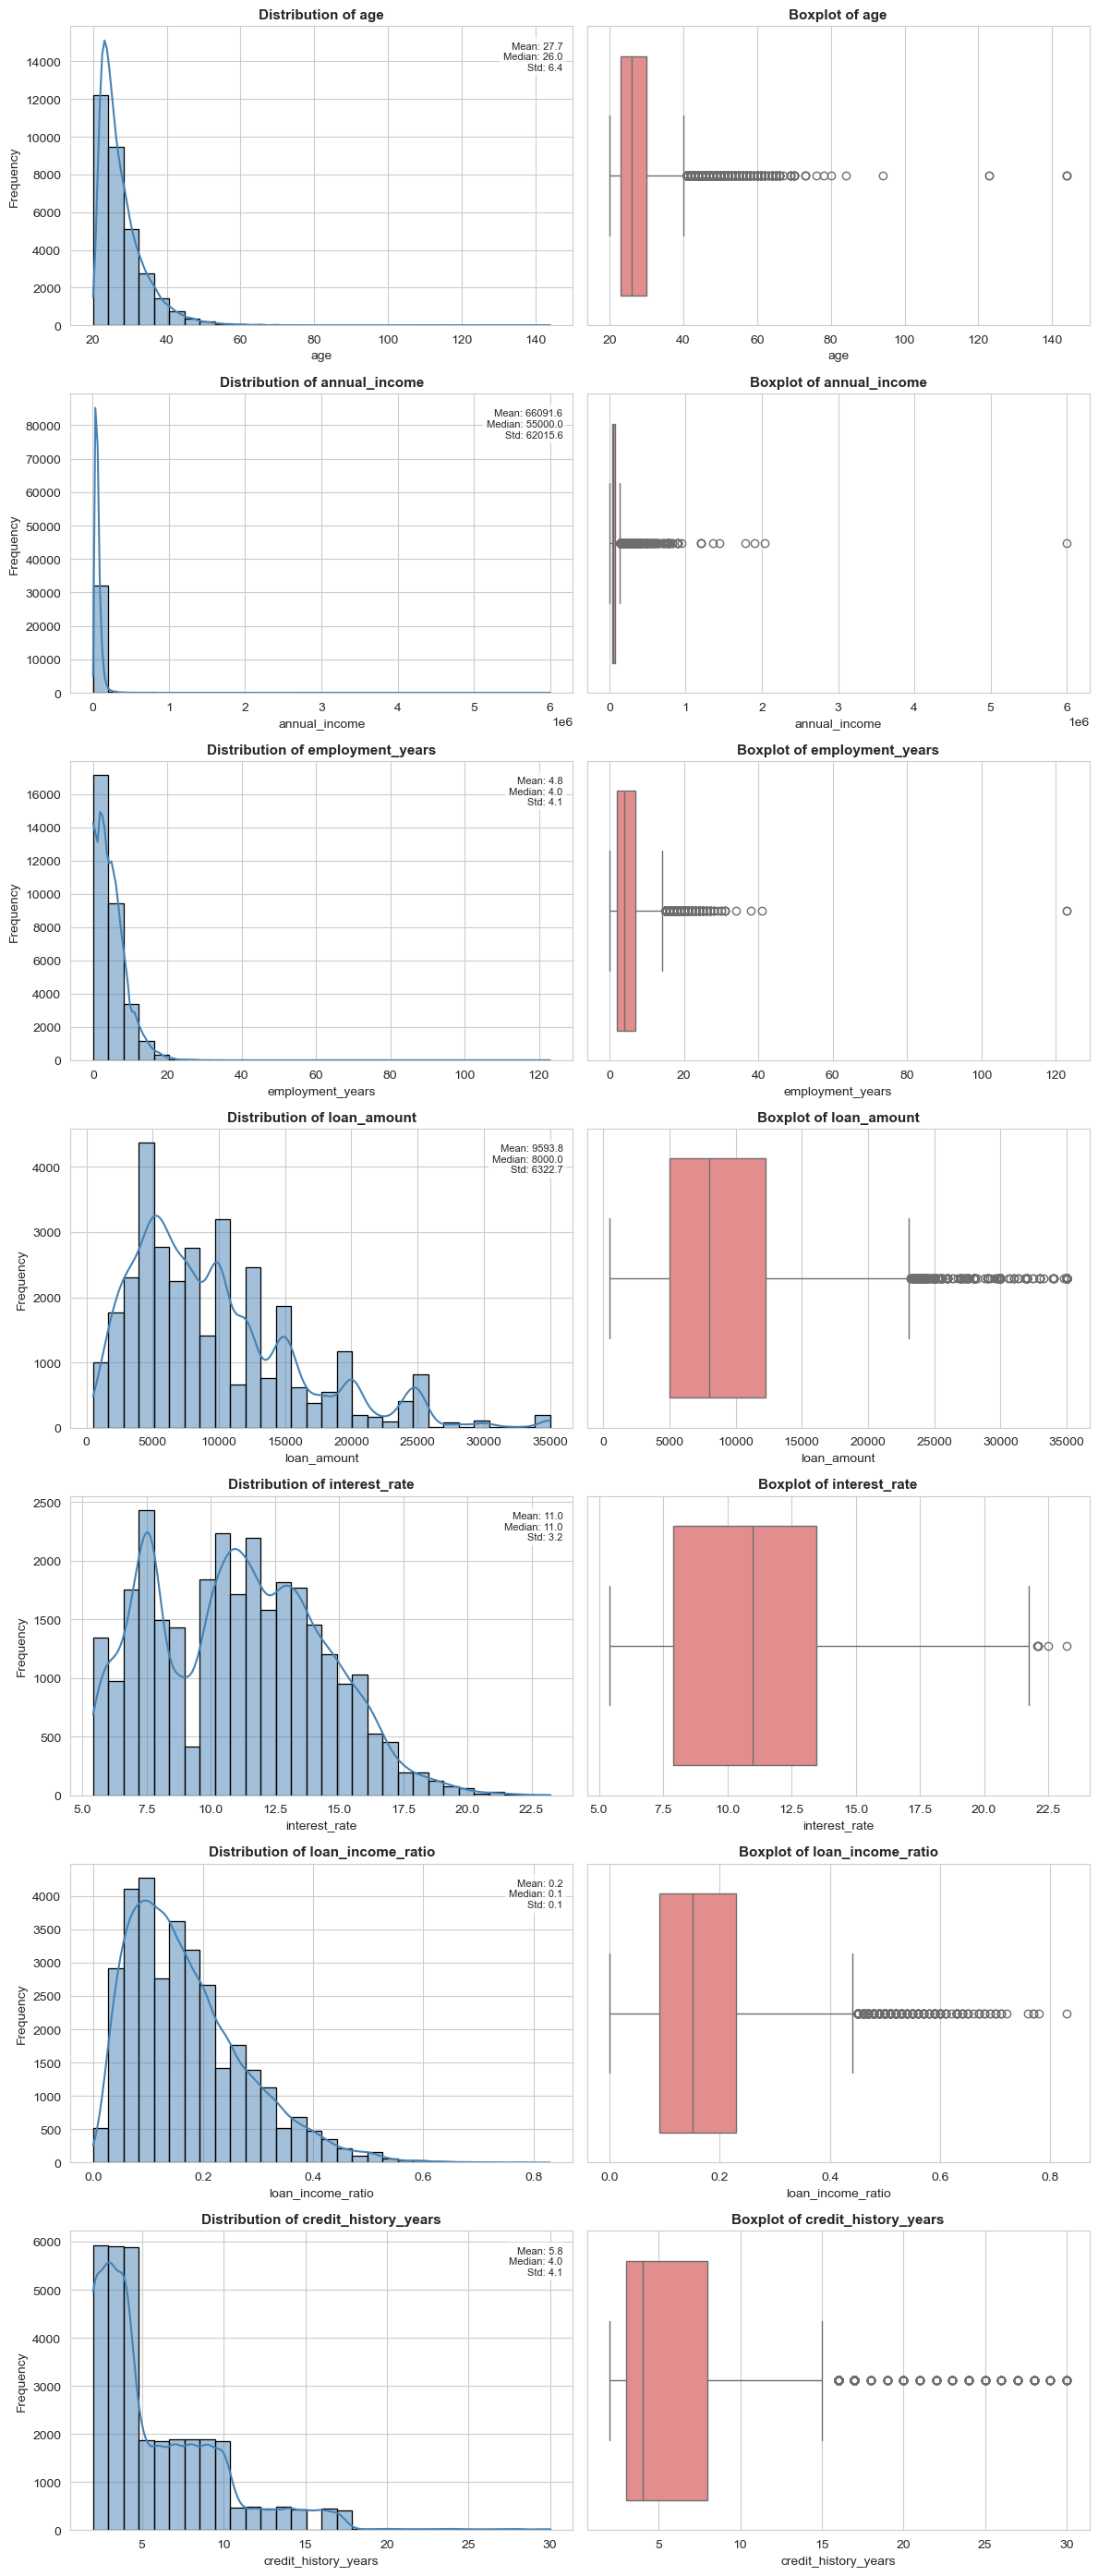

In [16]:
def univariate_numerical_plot(df, columns, bins=30, figsize_per_row=(12, 4)):
    """
    Plots histogram (left) + boxplot (right) for each numerical column in a grid.
    Automatically calculates number of rows based on number of columns provided.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataframe containing the data
    columns : str or list of str
        Single column name or list of numerical column names to plot
    bins : int, optional (default=30)
        Number of bins for histograms
    figsize_per_row : tuple, optional (default=(12,4))
        (width, height) allocated per row of plots
    """
    
    # Allow single column string input too
    if isinstance(columns, str):
        columns = [columns]
    
    n = len(columns)
    n_rows = n
    n_cols = 2  # histogram + boxplot, fixed
    
    fig_width, row_height = figsize_per_row
    fig, axes = plt.subplots(n_rows, n_cols, 
                              figsize=(fig_width, row_height * n_rows))
    
    # Ensure axes is always 2D array, even when n_rows == 1
    if n_rows == 1:
        axes = np.array([axes])
    
    for i, column in enumerate(columns):
        # Left: Histogram + KDE
        sns.histplot(data=df, x=column, bins=bins, kde=True,
                    color="steelblue", edgecolor="black", ax=axes[i, 0])
        axes[i, 0].set_title(f"Distribution of {column}", fontsize=11, fontweight="bold")
        axes[i, 0].set_xlabel(column)
        axes[i, 0].set_ylabel("Frequency")
        
        # Right: Boxplot
        sns.boxplot(data=df, x=column, color="lightcoral", ax=axes[i, 1])
        axes[i, 1].set_title(f"Boxplot of {column}", fontsize=11, fontweight="bold")
        axes[i, 1].set_xlabel(column)
        
        # Per-row stats as row-level annotation
        stats = df[column].describe()
        axes[i, 0].text(
            0.98, 0.95, 
            f"Mean: {stats['mean']:.1f}\nMedian: {df[column].median():.1f}\nStd: {stats['std']:.1f}",
            transform=axes[i, 0].transAxes,
            fontsize=8, va="top", ha="right",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7)
        )
    
    plt.tight_layout()
    plt.show()

univariate_numerical_plot(df,numeric_columns)

## Correlation

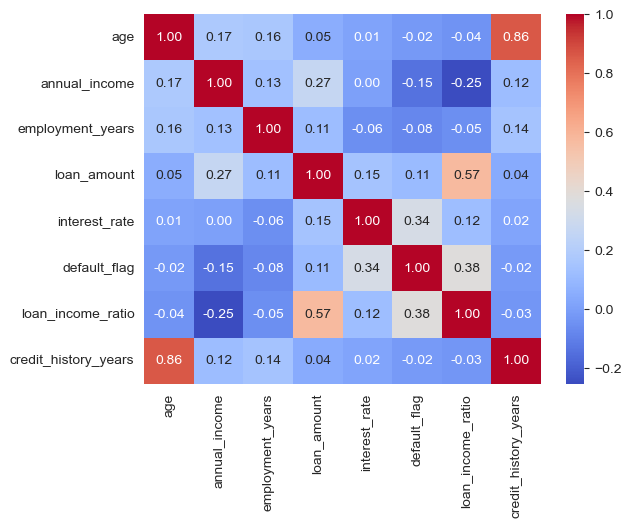

In [17]:
correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt  = ".2f"
)
plt.show()

# data cleaning 

In [26]:
df["home_ownership"] = df["home_ownership"].replace({
    "OTHER": "RENT"
})

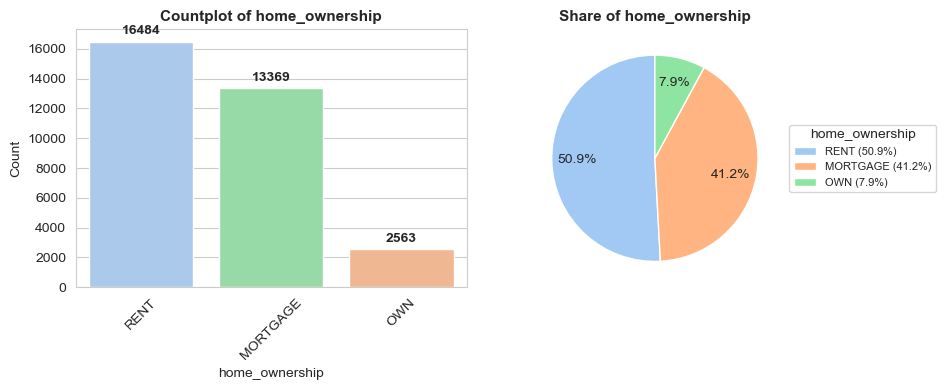

In [27]:
univariate_categorical_plot(df,'home_ownership' )

In [30]:
# Remove the extreame age values age can not exceed be > 100
df[df['age'] > 100]

,age,annual_income,home_ownership,employment_years,loan_purpose,credit_grade,loan_amount,interest_rate,default_flag,loan_income_ratio,prior_default_flag,credit_history_years
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


In [33]:
# drop the values
df.drop(df[df['age'] > 100].index, inplace=True)

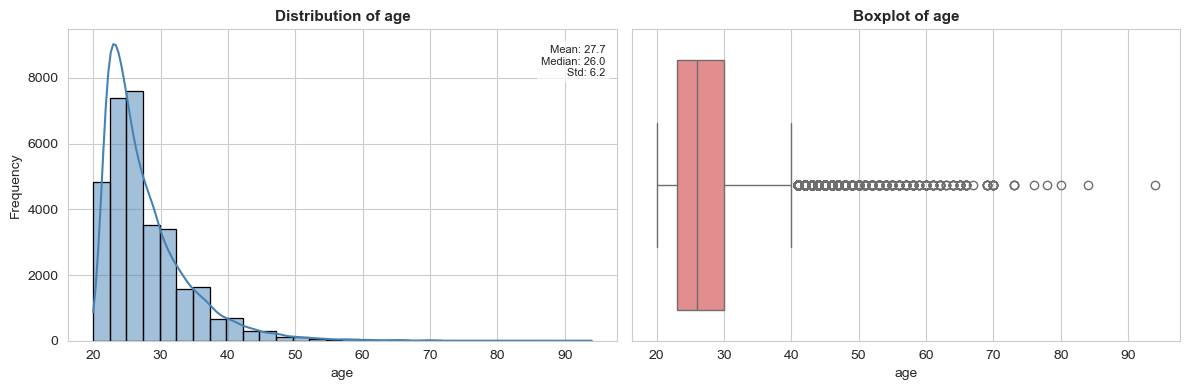

In [34]:
# after 
univariate_numerical_plot(df,'age')

In [35]:
# Remove the extreme employment years
df[df['employment_years'] > 100]

,age,annual_income,home_ownership,employment_years,loan_purpose,credit_grade,loan_amount,interest_rate,default_flag,loan_income_ratio,prior_default_flag,credit_history_years
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [ ]:
# drop operation
df.drop(df[df['employment_years'] > 100].index,inplace = True)

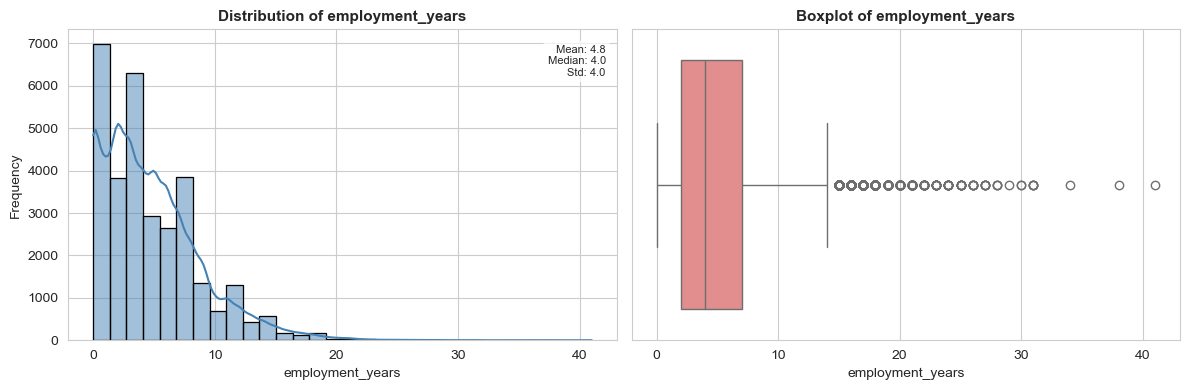

In [38]:
# after
univariate_numerical_plot(df,'employment_years')